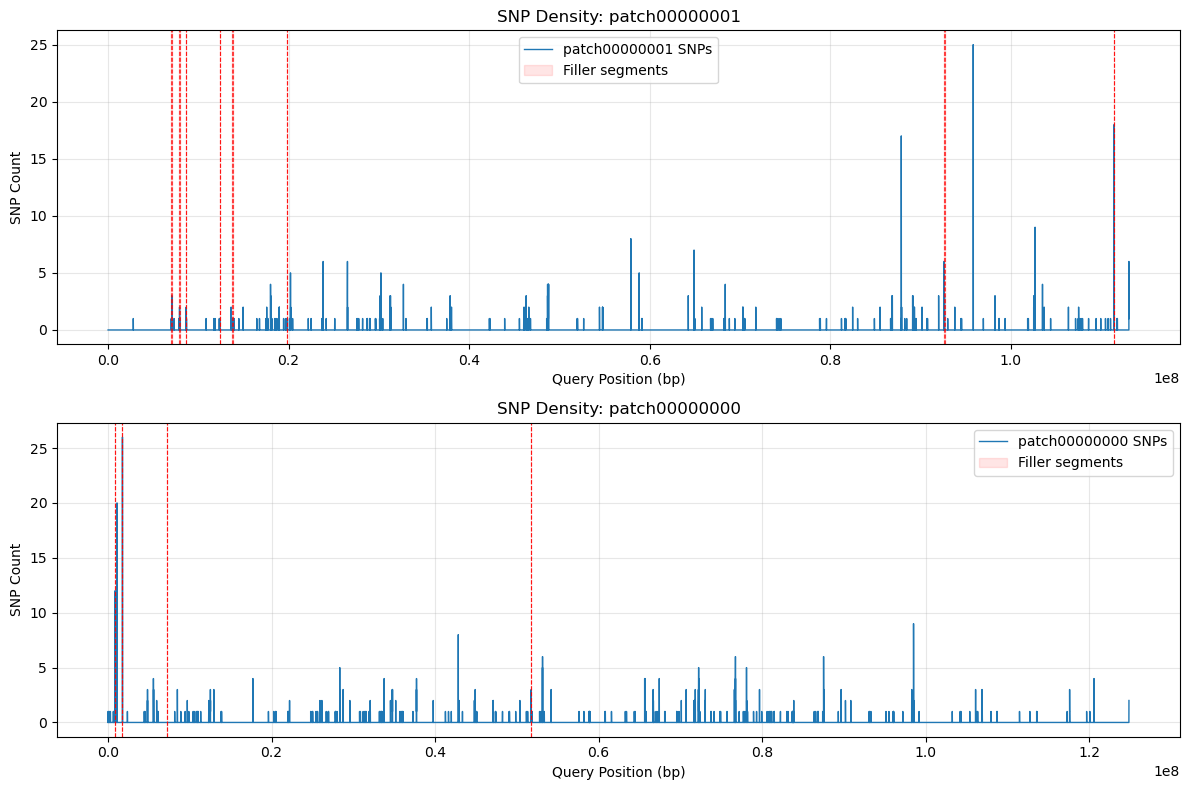

Filler segment boundaries and SNP counts:
patch00000000: 4 filler segments
856,007 - 858,860, 0->1 (length: 2,854 bp, SNPs: 6, Ratio: 0.21%)
1,758,990 - 1,762,564, 1->2 (length: 3,575 bp, SNPs: 35, Ratio: 0.98%)
7,196,124 - 7,197,861, 2->3 (length: 1,738 bp, SNPs: 0, Ratio: 0.00%)
51,753,512 - 51,756,191, 3->5 (length: 2,680 bp, SNPs: 0, Ratio: 0.00%)
patch00000001: 8 filler segments
7,002,777 - 7,127,350, 12->13 (length: 124,574 bp, SNPs: 16, Ratio: 0.01%)
7,863,785 - 7,987,899, 13->14 (length: 124,115 bp, SNPs: 11, Ratio: 0.01%)
8,601,472 - 8,634,826, 14->15 (length: 33,355 bp, SNPs: 3, Ratio: 0.01%)
12,349,722 - 12,397,166, 17->18 (length: 47,445 bp, SNPs: 2, Ratio: 0.00%)
13,772,133 - 13,784,986, 18->19 (length: 12,854 bp, SNPs: 1, Ratio: 0.01%)
19,805,471 - 19,814,117, 19->20 (length: 8,647 bp, SNPs: 1, Ratio: 0.01%)
92,565,285 - 92,640,970, 21->22 (length: 75,686 bp, SNPs: 60, Ratio: 0.08%)
111,426,679 - 111,432,290, 23->24 (length: 5,612 bp, SNPs: 34, Ratio: 0.61%)


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Parameters
snps_file = "compare_patch/close_patch_0728/pan_dist_to_GT.chr1.hap2.snps"
agp_file = "0722_patch/HG002.chr1.hap2.close_patch_aggregate.agp"  # Update path as needed
bin_size = 1000  # Change as needed

# Read the .snps file, skipping comment lines
df = pd.read_csv(snps_file, sep='\t', comment='#', header=None)
df = df[(df[1] != '.') & (df[2] != '.')]

# Parse AGP file to get filler segment boundaries
filler_boundaries = {}
filler_names = {}
with open(agp_file, 'r') as f:
    list_line = list(f)
    for idx, line in enumerate(list_line):
        if line.startswith('#'):
            continue
        fields = line.strip().split('\t')
        patch_name = fields[0]
        start_pos = int(fields[1])
        end_pos = int(fields[2])
        contig_name = fields[5]
        
        # Check if this is a filler segment (not starting with "chr1_RagTag_")
        if not contig_name.startswith("chr1_RagTag_"):
            if patch_name not in filler_boundaries:
                filler_boundaries[patch_name] = []
            filler_names[start_pos] = list_line[idx-1].split('\t')[5].split('_')[-1] + '->' + list_line[idx+1].split('\t')[5].split('_')[-1] 
            filler_boundaries[patch_name].append((start_pos, end_pos))


# Extract relevant columns
contigs = df[df.columns[-1]].unique()
n_contigs = len(contigs)

# Set up subplots (1 column, n_contigs rows)
fig, axes = plt.subplots(n_contigs, 1, figsize=(12, 4 * n_contigs), sharex=False)

# If only one contig, axes is not a list, so make it a list
if n_contigs == 1:
    axes = [axes]

for ax, contig in zip(axes, contigs):
    group = df[df[df.columns[-1]] == contig]
    positions = group[3]
    max_pos = positions.max()
    bins = np.arange(0, max_pos + bin_size, bin_size)
    counts, _ = np.histogram(positions, bins=bins)
    
    # Filter bins where count > 300 (optional)
    mask = counts <= 300
    filtered_bins = bins[:-1][mask]
    filtered_counts = counts[mask]
    
    # Plot SNP density
    ax.plot(filtered_bins, filtered_counts, label=f'{contig} SNPs', linewidth=1)
    
    # Add vertical lines for filler segment boundaries
    if contig in filler_boundaries:
        for start, end in filler_boundaries[contig]:
            # Add lines at start and end positions
            ax.axvline(x=start, color='red', linestyle='--', alpha=0.7, linewidth=0.8)
            ax.axvline(x=end, color='red', linestyle='--', alpha=0.7, linewidth=0.8)
            # Shade the filler region
            ax.axvspan(start, end, alpha=0.1, color='red', label='Filler segments' if start == filler_boundaries[contig][0][0] else "")
    
    ax.set_title(f'SNP Density: {contig}')
    ax.set_xlabel('Query Position (bp)')
    ax.set_ylabel('SNP Count')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary of filler segments with SNP counts
print("Filler segment boundaries and SNP counts:")
for contig, boundaries in filler_boundaries.items():
    print(f"{contig}: {len(boundaries)} filler segments")
    
    # Get SNPs for this contig
    contig_snps = df[df[df.columns[-1]] == contig] 
    for start, end in boundaries:
        # Count SNPs in this region
        if start in filler_names:
            filler_name = filler_names[start]
        else:
            filler_name = "unknown"
        
        snps_in_region = contig_snps[(contig_snps[3] >= start) & (contig_snps[3] <= end)]
        snp_count = len(snps_in_region)
        print(f"{start:,} - {end:,}, {filler_name} (length: {end-start+1:,} bp, SNPs: {snp_count}, Ratio: {snp_count/(end-start+1):.2%})")

## ================== chr1 hap1 ====================

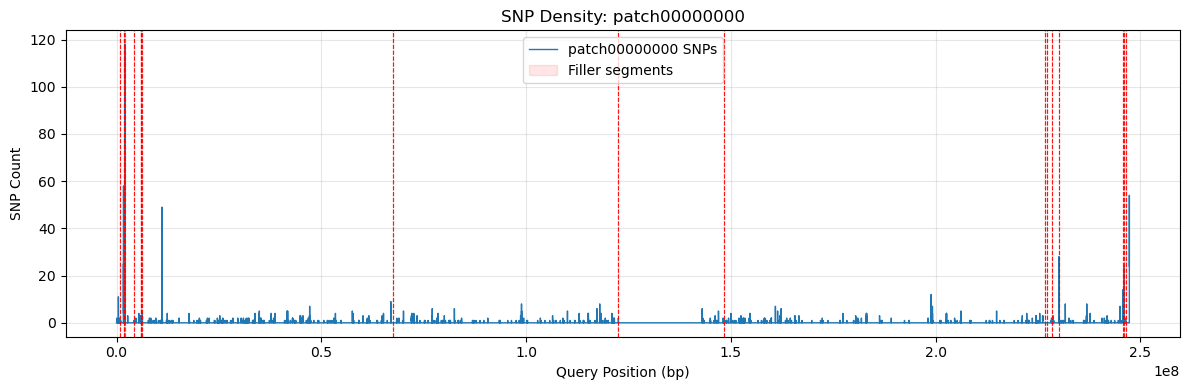

Filler segment boundaries and SNP counts:
patch00000000: 17 filler segments
729,844 - 831,491, 0->1 (length: 101,648 bp, SNPs: 3, Ratio: 0.00%)
1,706,876 - 1,710,954, 1->2 (length: 4,079 bp, SNPs: 64, Ratio: 1.57%)
1,859,610 - 2,135,955, 2->3 (length: 276,346 bp, SNPs: 220, Ratio: 0.08%)
4,350,325 - 4,361,512, 3->4 (length: 11,188 bp, SNPs: 1, Ratio: 0.01%)
5,853,476 - 5,880,193, 4->5 (length: 26,718 bp, SNPs: 2, Ratio: 0.01%)
5,996,809 - 6,002,596, 5->6 (length: 5,788 bp, SNPs: 0, Ratio: 0.00%)
6,300,732 - 6,303,367, 6->11 (length: 2,636 bp, SNPs: 4, Ratio: 0.15%)
67,583,105 - 67,590,927, 11->12 (length: 7,823 bp, SNPs: 0, Ratio: 0.00%)
122,330,295 - 122,367,237, 12->13 (length: 36,943 bp, SNPs: 0, Ratio: 0.00%)
148,259,720 - 148,274,952, 17->18 (length: 15,233 bp, SNPs: 2, Ratio: 0.01%)
226,813,426 - 226,824,517, 18->19 (length: 11,092 bp, SNPs: 0, Ratio: 0.00%)
227,271,114 - 227,271,835, 19->20 (length: 722 bp, SNPs: 0, Ratio: 0.00%)
228,306,483 - 228,329,357, 20->21 (length: 22,875

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Parameters
snps_file = "compare_patch/close_patch_0728/pan_dist_to_GT.diff.snps"
agp_file = "0722_patch/HG002.chr1.hap1.close_patch_aggregate.agp"  # Update path as needed
bin_size = 1000  # Change as needed

# Read the .snps file, skipping comment lines
df = pd.read_csv(snps_file, sep='\t', comment='#', header=None)
df = df[(df[1] != '.') & (df[2] != '.')]

# Parse AGP file to get filler segment boundaries
filler_boundaries = {}
filler_names = {}
with open(agp_file, 'r') as f:
    list_line = list(f)
    for idx, line in enumerate(list_line):
        if line.startswith('#'):
            continue
        fields = line.strip().split('\t')
        patch_name = fields[0]
        start_pos = int(fields[1])
        end_pos = int(fields[2])
        contig_name = fields[5]
        
        # Check if this is a filler segment (not starting with "chr1_RagTag_")
        if not contig_name.startswith("chr1_RagTag_"):
            if patch_name not in filler_boundaries:
                filler_boundaries[patch_name] = []
            filler_names[start_pos] = list_line[idx-1].split('\t')[5].split('_')[-1] + '->' + list_line[idx+1].split('\t')[5].split('_')[-1] 
            filler_boundaries[patch_name].append((start_pos, end_pos))


# Extract relevant columns
contigs = df[df.columns[-1]].unique()
n_contigs = len(contigs)

# Set up subplots (1 column, n_contigs rows)
fig, axes = plt.subplots(n_contigs, 1, figsize=(12, 4 * n_contigs), sharex=False)

# If only one contig, axes is not a list, so make it a list
if n_contigs == 1:
    axes = [axes]

for ax, contig in zip(axes, contigs):
    group = df[df[df.columns[-1]] == contig]
    positions = group[3]
    max_pos = positions.max()
    bins = np.arange(0, max_pos + bin_size, bin_size)
    counts, _ = np.histogram(positions, bins=bins)
    
    # Filter bins where count > 300 (optional)
    mask = counts <= 300
    filtered_bins = bins[:-1][mask]
    filtered_counts = counts[mask]
    
    # Plot SNP density
    ax.plot(filtered_bins, filtered_counts, label=f'{contig} SNPs', linewidth=1)
    
    # Add vertical lines for filler segment boundaries
    if contig in filler_boundaries:
        for start, end in filler_boundaries[contig]:
            # Add lines at start and end positions
            ax.axvline(x=start, color='red', linestyle='--', alpha=0.7, linewidth=0.8)
            ax.axvline(x=end, color='red', linestyle='--', alpha=0.7, linewidth=0.8)
            # Shade the filler region
            ax.axvspan(start, end, alpha=0.1, color='red', label='Filler segments' if start == filler_boundaries[contig][0][0] else "")
    
    ax.set_title(f'SNP Density: {contig}')
    ax.set_xlabel('Query Position (bp)')
    ax.set_ylabel('SNP Count')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary of filler segments with SNP counts
print("Filler segment boundaries and SNP counts:")
for contig, boundaries in filler_boundaries.items():
    print(f"{contig}: {len(boundaries)} filler segments")
    
    # Get SNPs for this contig
    contig_snps = df[df[df.columns[-1]] == contig] 
    for start, end in boundaries:
        # Count SNPs in this region
        if start in filler_names:
            filler_name = filler_names[start]
        else:
            filler_name = "unknown"
        
        snps_in_region = contig_snps[(contig_snps[3] >= start) & (contig_snps[3] <= end)]
        snp_count = len(snps_in_region)
        print(f"{start:,} - {end:,}, {filler_name} (length: {end-start+1:,} bp, SNPs: {snp_count}, Ratio: {snp_count/(end-start+1):.2%})")



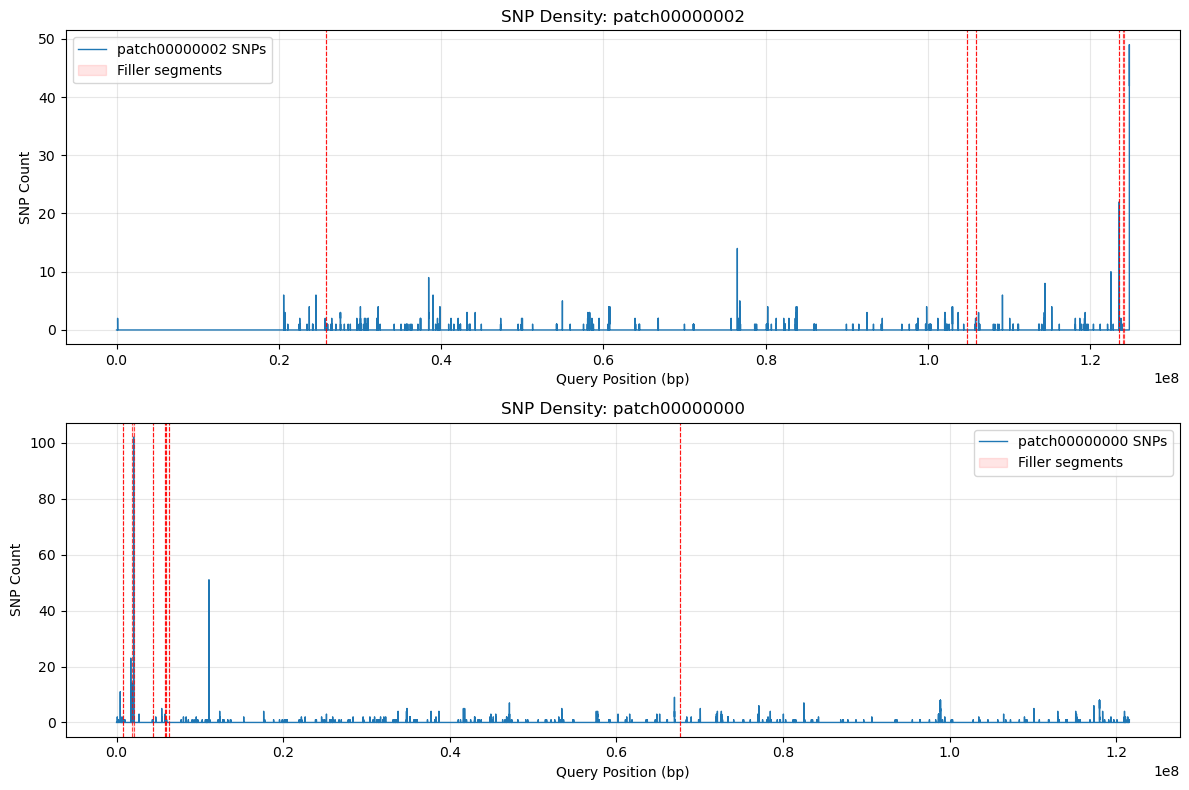

Filler segment boundaries and SNP counts:
patch00000000: 7 filler segments
729,844 - 831,491, 0->1 (length: 101,648 bp, SNPs: 3, Ratio: 0.00%)
1,849,516 - 2,125,861, 2->3 (length: 276,346 bp, SNPs: 220, Ratio: 0.08%)
4,340,231 - 4,351,418, 3->4 (length: 11,188 bp, SNPs: 1, Ratio: 0.01%)
5,843,382 - 5,870,099, 4->5 (length: 26,718 bp, SNPs: 2, Ratio: 0.01%)
5,986,715 - 5,992,504, 5->6 (length: 5,790 bp, SNPs: 0, Ratio: 0.00%)
6,290,640 - 6,293,404, 6->11 (length: 2,765 bp, SNPs: 0, Ratio: 0.00%)
67,573,142 - 67,580,964, 11->12 (length: 7,823 bp, SNPs: 0, Ratio: 0.00%)
patch00000001: 3 filler segments
69,472 - 77,881, 7->8 (length: 8,410 bp, SNPs: 0, Ratio: 0.00%)
238,677 - 3,601,502, 8->9 (length: 3,362,826 bp, SNPs: 0, Ratio: 0.00%)
3,630,156 - 4,174,684, 9->10 (length: 544,529 bp, SNPs: 0, Ratio: 0.00%)
patch00000002: 5 filler segments
25,851,596 - 25,854,486, 17->18 (length: 2,891 bp, SNPs: 0, Ratio: 0.00%)
104,814,887 - 104,815,608, 19->20 (length: 722 bp, SNPs: 0, Ratio: 0.00%)
105

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Parameters
snps_file = "compare_patch/chr1.hap1.pangenome_patch_to_GT.diff.snps"
agp_file = "0710_patch/pan_patch/chr1/HG002.hap1.pan_patch.agp"  # Update path as needed
bin_size = 1000  # Change as needed

# Read the .snps file, skipping comment lines
df = pd.read_csv(snps_file, sep='\t', comment='#', header=None)
df = df[(df[1] != '.') & (df[2] != '.')]

# Parse AGP file to get filler segment boundaries
filler_boundaries = {}
filler_names = {}
with open(agp_file, 'r') as f:
    list_line = list(f)
    for idx, line in enumerate(list_line):
        if line.startswith('#'):
            continue
        fields = line.strip().split('\t')
        patch_name = fields[0]
        start_pos = int(fields[1])
        end_pos = int(fields[2])
        contig_name = fields[5]
        
        # Check if this is a filler segment (not starting with "chr1_RagTag_")
        if not contig_name.startswith("chr1_RagTag_"):
            if patch_name not in filler_boundaries:
                filler_boundaries[patch_name] = []
            filler_names[start_pos] = list_line[idx-1].split('\t')[5].split('_')[-1] + '->' + list_line[idx+1].split('\t')[5].split('_')[-1] 
            filler_boundaries[patch_name].append((start_pos, end_pos))


# Extract relevant columns
contigs = df[df.columns[-1]].unique()
n_contigs = len(contigs)

# Set up subplots (1 column, n_contigs rows)
fig, axes = plt.subplots(n_contigs, 1, figsize=(12, 4 * n_contigs), sharex=False)

# If only one contig, axes is not a list, so make it a list
if n_contigs == 1:
    axes = [axes]

for ax, contig in zip(axes, contigs):
    group = df[df[df.columns[-1]] == contig]
    positions = group[3]
    max_pos = positions.max()
    bins = np.arange(0, max_pos + bin_size, bin_size)
    counts, _ = np.histogram(positions, bins=bins)
    
    # Filter bins where count > 300 (optional)
    mask = counts <= 300
    filtered_bins = bins[:-1][mask]
    filtered_counts = counts[mask]
    
    # Plot SNP density
    ax.plot(filtered_bins, filtered_counts, label=f'{contig} SNPs', linewidth=1)
    
    # Add vertical lines for filler segment boundaries
    if contig in filler_boundaries:
        for start, end in filler_boundaries[contig]:
            # Add lines at start and end positions
            ax.axvline(x=start, color='red', linestyle='--', alpha=0.7, linewidth=0.8)
            ax.axvline(x=end, color='red', linestyle='--', alpha=0.7, linewidth=0.8)
            # Shade the filler region
            ax.axvspan(start, end, alpha=0.1, color='red', label='Filler segments' if start == filler_boundaries[contig][0][0] else "")
    
    ax.set_title(f'SNP Density: {contig}')
    ax.set_xlabel('Query Position (bp)')
    ax.set_ylabel('SNP Count')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary of filler segments with SNP counts
print("Filler segment boundaries and SNP counts:")
for contig, boundaries in filler_boundaries.items():
    print(f"{contig}: {len(boundaries)} filler segments")
    
    # Get SNPs for this contig
    contig_snps = df[df[df.columns[-1]] == contig] 
    for start, end in boundaries:
        # Count SNPs in this region
        if start in filler_names:
            filler_name = filler_names[start]
        else:
            filler_name = "unknown"
        
        snps_in_region = contig_snps[(contig_snps[3] >= start) & (contig_snps[3] <= end)]
        snp_count = len(snps_in_region)
        print(f"{start:,} - {end:,}, {filler_name} (length: {end-start+1:,} bp, SNPs: {snp_count}, Ratio: {snp_count/(end-start+1):.2%})")



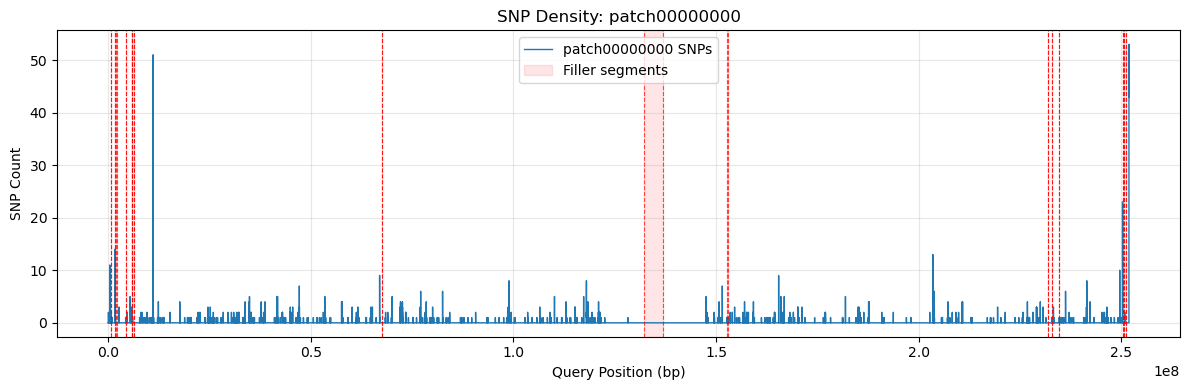

Filler segment boundaries and SNP counts:
patch00000000: 16 filler segments
729,844 - 831,496, 0->1 (length: 101,653 bp, SNPs: 0, Ratio: 0.00%)
1,706,881 - 1,709,012, 1->2 (length: 2,132 bp, SNPs: 0, Ratio: 0.00%)
1,857,668 - 2,155,809, 2->3 (length: 298,142 bp, SNPs: 0, Ratio: 0.00%)
4,370,179 - 4,381,362, 3->4 (length: 11,184 bp, SNPs: 0, Ratio: 0.00%)
5,873,326 - 5,900,043, 4->5 (length: 26,718 bp, SNPs: 0, Ratio: 0.00%)
6,016,659 - 6,022,447, 5->6 (length: 5,789 bp, SNPs: 0, Ratio: 0.00%)
6,320,583 - 6,323,413, 6->11 (length: 2,831 bp, SNPs: 0, Ratio: 0.00%)
67,603,151 - 67,610,973, 11->12 (length: 7,823 bp, SNPs: 0, Ratio: 0.00%)
132,331,540 - 136,822,293, 14->16 (length: 4,490,754 bp, SNPs: 0, Ratio: 0.00%)
152,800,308 - 152,815,512, 17->18 (length: 15,205 bp, SNPs: 0, Ratio: 0.00%)
231,796,007 - 231,796,728, 19->20 (length: 722 bp, SNPs: 0, Ratio: 0.00%)
232,831,376 - 232,854,251, 20->21 (length: 22,876 bp, SNPs: 0, Ratio: 0.00%)
234,642,887 - 234,648,560, 21->22 (length: 5,674 

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Parameters
snps_file = "compare_patch/chr1.hap1.donor_patch_to_GT.diff.snps"
agp_file = "0706_patch_relax/chr1/HG002.hap1.HG002.1.agp"  # Update path as needed
bin_size = 1000  # Change as needed

# Read the .snps file, skipping comment lines
df = pd.read_csv(snps_file, sep='\t', comment='#', header=None)
df = df[(df[1] != '.') & (df[2] != '.')]

# Parse AGP file to get filler segment boundaries
filler_boundaries = {}
filler_names = {}
with open(agp_file, 'r') as f:
    list_line = list(f)
    for idx, line in enumerate(list_line):
        if line.startswith('#'):
            continue
        fields = line.strip().split('\t')
        patch_name = fields[0]
        start_pos = int(fields[1])
        end_pos = int(fields[2])
        contig_name = fields[5]
        
        # Check if this is a filler segment (not starting with "chr1_RagTag_")
        if not contig_name.startswith("chr1_RagTag_"):
            if patch_name not in filler_boundaries:
                filler_boundaries[patch_name] = []
            filler_names[start_pos] = list_line[idx-1].split('\t')[5].split('_')[-1] + '->' + list_line[idx+1].split('\t')[5].split('_')[-1] 
            filler_boundaries[patch_name].append((start_pos, end_pos))


# Extract relevant columns
contigs = df[df.columns[-1]].unique()
n_contigs = len(contigs)

# Set up subplots (1 column, n_contigs rows)
fig, axes = plt.subplots(n_contigs, 1, figsize=(12, 4 * n_contigs), sharex=False)

# If only one contig, axes is not a list, so make it a list
if n_contigs == 1:
    axes = [axes]

for ax, contig in zip(axes, contigs):
    group = df[df[df.columns[-1]] == contig]
    positions = group[3]
    max_pos = positions.max()
    bins = np.arange(0, max_pos + bin_size, bin_size)
    counts, _ = np.histogram(positions, bins=bins)
    
    # Filter bins where count > 300 (optional)
    mask = counts <= 300
    filtered_bins = bins[:-1][mask]
    filtered_counts = counts[mask]
    
    # Plot SNP density
    ax.plot(filtered_bins, filtered_counts, label=f'{contig} SNPs', linewidth=1)
    
    # Add vertical lines for filler segment boundaries
    if contig in filler_boundaries:
        for start, end in filler_boundaries[contig]:
            # Add lines at start and end positions
            ax.axvline(x=start, color='red', linestyle='--', alpha=0.7, linewidth=0.8)
            ax.axvline(x=end, color='red', linestyle='--', alpha=0.7, linewidth=0.8)
            # Shade the filler region
            ax.axvspan(start, end, alpha=0.1, color='red', label='Filler segments' if start == filler_boundaries[contig][0][0] else "")
    
    ax.set_title(f'SNP Density: {contig}')
    ax.set_xlabel('Query Position (bp)')
    ax.set_ylabel('SNP Count')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary of filler segments with SNP counts
print("Filler segment boundaries and SNP counts:")
for contig, boundaries in filler_boundaries.items():
    print(f"{contig}: {len(boundaries)} filler segments")
    
    # Get SNPs for this contig
    contig_snps = df[df[df.columns[-1]] == contig] 
    for start, end in boundaries:
        # Count SNPs in this region
        if start in filler_names:
            filler_name = filler_names[start]
        else:
            filler_name = "unknown"
        
        snps_in_region = contig_snps[(contig_snps[3] >= start) & (contig_snps[3] <= end)]
        snp_count = len(snps_in_region)
        print(f"{start:,} - {end:,}, {filler_name} (length: {end-start+1:,} bp, SNPs: {snp_count}, Ratio: {snp_count/(end-start+1):.2%})")



## ======================== Before 07/28 ==========================
## ============================================================

In [26]:
dict_regions = {}
f = open("0722_patch/HG002.chr1.hap1.close_patch_aggregate.agp")
for line in f:
    if line.startswith("#"):
        continue
    fields = line.strip().split("\t")
    patch = fields[0]
    contig = fields[5]
    start = int(fields[1])
    end = int(fields[2])
    if patch == "patch00000001":
        continue
    dict_regions[(start, end)] = contig
f.close()

df = pd.read_csv(snps_file, sep='\t', comment='#', header=None)
df = df[(df[1] != '.') & (df[2] != '.')]
sorted_df = df.sort_values(by=3)
print(f"total snp count: {len(sorted_df)}")
# Extract relevant columns
last_idx = 0
for region, contig in sorted(dict_regions.items()):
    snp_count = 0
    start, end = region
    for i in range(last_idx, len(df)):
        if sorted_df.iloc[i][3] >= start:
            print(start, sorted_df.iloc[i][3])
            break
    for j in range(i, len(df)):
        if sorted_df.iloc[j][3] > end:
            print(end, sorted_df.iloc[j][3])
            snp_count += 1
            break
    print(f"region: {dict_regions[(start, end)]}, {start} - {end} contig: {contig}, snp_count: {snp_count}")
    last_idx = j
    print("last_idx", last_idx)

total snp count: 200970
1 90363
729843 729845
region: chr1_RagTag_0, 1 - 729843 contig: chr1_RagTag_0, snp_count: 1
last_idx 19
729844 729845
831491 843656
region: HG00272.1_chr1, 729844 - 831491 contig: HG00272.1_chr1, snp_count: 1
last_idx 76985
831492 843656
1706875 1706876
region: chr1_RagTag_1, 831492 - 1706875 contig: chr1_RagTag_1, snp_count: 1
last_idx 77021
1706876 1706876
1710954 1722110
region: HG00232.1_chr1, 1706876 - 1710954 contig: HG00232.1_chr1, snp_count: 1
last_idx 77803
1710955 1722110
1859609 1864681
region: chr1_RagTag_2, 1710955 - 1859609 contig: chr1_RagTag_2, snp_count: 1
last_idx 77808
1859610 1864681
2135955 2715312
region: HG04115.2_chr1, 1859610 - 2135955 contig: HG04115.2_chr1, snp_count: 1
last_idx 78028
2135956 2715312
4350324 4350326
region: chr1_RagTag_3, 2135956 - 4350324 contig: chr1_RagTag_3, snp_count: 1
last_idx 78034
4350325 4350326
4361512 4399132
region: HG00133.2_chr1, 4350325 - 4361512 contig: HG00133.2_chr1, snp_count: 1
last_idx 86575
43615

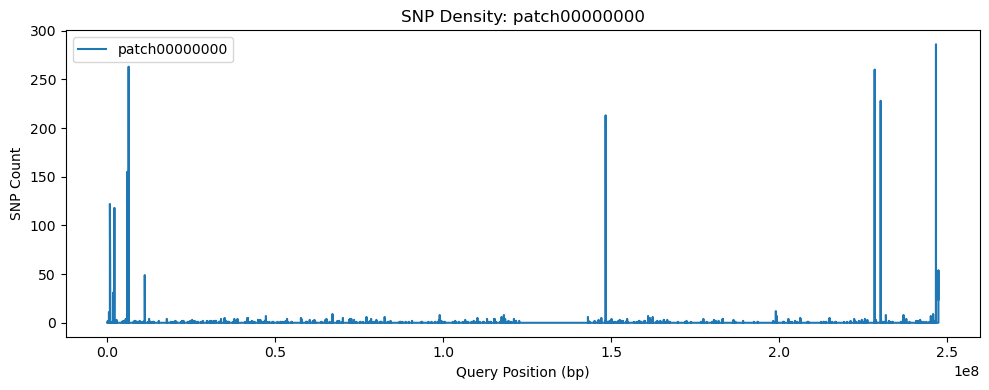

200970 5496


In [8]:
# Parameters
snps_file = "compare_patch/close_patch/pan_dist_to_GT.diff.snps"
bin_size = 1000  # Change as needed

# Read the .snps file, skipping comment lines
df = pd.read_csv(snps_file, sep='\t', comment='#', header=None)
df = df[(df[1] != '.') & (df[2] != '.')]

# Extract relevant columns

contigs = df[df.columns[-1]].unique()
n_contigs = len(contigs)

# Set up subplots (1 column, n_contigs rows)
fig, axes = plt.subplots(n_contigs, 1, figsize=(10, 4 * n_contigs), sharex=False)

# If only one contig, axes is not a list, so make it a list
if n_contigs == 1:
    axes = [axes]

for ax, contig in zip(axes, contigs):
    group = df[df[df.columns[-1]] == contig]
    positions = group[3]
    max_pos = positions.max()
    bins = np.arange(0, max_pos + bin_size, bin_size)
    counts, _ = np.histogram(positions, bins=bins)

    # Filter bins where count > 300
    mask = counts <= 300
    filtered_bins = bins[:-1][mask]
    filtered_counts = counts[mask]
    
    ax.plot(filtered_bins, filtered_counts, label=contig)
    ax.set_title(f'SNP Density: {contig}')
    ax.set_xlabel('Query Position (bp)')
    ax.set_ylabel('SNP Count')
    ax.legend()

plt.tight_layout()
plt.show()
print(sum(counts), sum(filtered_counts))

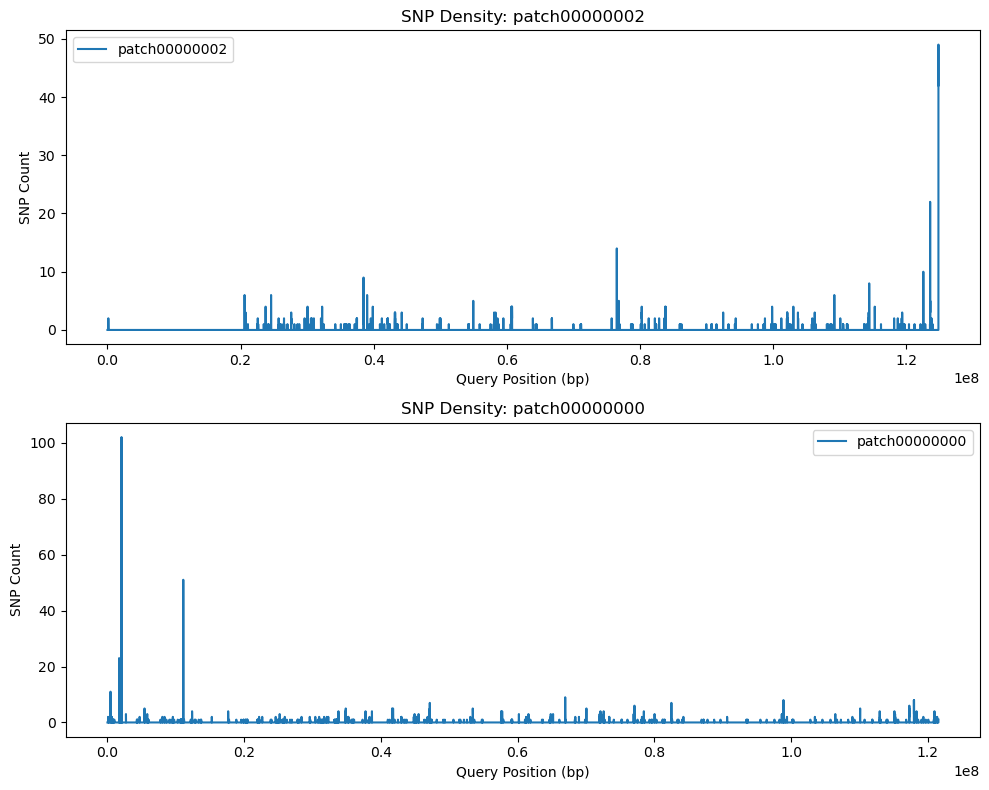

In [3]:
snps_file = "compare_patch/chr1.hap1.pangenome_patch_to_GT.diff.snps"
bin_size = 1000  # Change as needed

# Read the .snps file, skipping comment lines
df = pd.read_csv(snps_file, sep='\t', comment='#', header=None)
df = df[(df[1] != '.') & (df[2] != '.')]

# Extract relevant columns

contigs = df[df.columns[-1]].unique()
n_contigs = len(contigs)

# Set up subplots (1 column, n_contigs rows)
fig, axes = plt.subplots(n_contigs, 1, figsize=(10, 4 * n_contigs), sharex=False)

# If only one contig, axes is not a list, so make it a list
if n_contigs == 1:
    axes = [axes]

for ax, contig in zip(axes, contigs):
    group = df[df[df.columns[-1]] == contig]
    positions = group[3]
    max_pos = positions.max()
    bins = np.arange(0, max_pos + bin_size, bin_size)
    counts, _ = np.histogram(positions, bins=bins)
    ax.plot(bins[:-1], counts, label=contig)
    ax.set_title(f'SNP Density: {contig}')
    ax.set_xlabel('Query Position (bp)')
    ax.set_ylabel('SNP Count')
    ax.legend()

plt.tight_layout()
plt.show()